<a href="https://colab.research.google.com/github/mominanoor/Machine-Learning/blob/main/Cross_Validation_Lasso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import loadtxt, logspace
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score

In [15]:
%%writefile ex1data1.txt
6.1101,17.592
5.5277,9.1302
8.5186,13.662
7.0032,11.854
5.8598,6.8233
8.3829,11.886
7.4764,4.3483
8.5781,12
6.4862,6.5987
5.0546,3.8166
5.7107,3.2522
14.164,15.505
5.734,3.1551
8.4084,7.2258
5.6407,0.71618
5.3794,3.5129
6.3654,5.3048
5.1301,0.56077
6.4296,3.6518
7.0708,5.3893
6.1891,3.1386
20.27,21.767
5.4901,4.263
6.3261,5.1875
5.5649,3.0825
18.945,22.638
12.828,13.501
10.957,7.0467
13.176,14.692
22.203,24.147
5.2524,-1.22
6.5894,5.9966
9.2482,12.134
5.8918,1.8495
8.2111,6.5426
7.9334,4.5623
8.0959,4.1164
5.6063,3.3928
12.836,10.117
6.3534,5.4974
5.4069,0.55657
6.8825,3.9115
11.708,5.3854
5.7737,2.4406
7.8247,6.7318
7.0931,1.0463
5.0702,5.1337
5.8014,1.844
11.7,8.0043
5.5416,1.0179
7.5402,6.7504
5.3077,1.8396
7.4239,4.2885
7.6031,4.9981
6.3328,1.4233
6.3589,-1.4211
6.2742,2.4756
5.6397,4.6042
9.3102,3.9624
9.4536,5.4141
8.8254,5.1694
5.1793,-0.74279
21.279,17.929
14.908,12.054
18.959,17.054
7.2182,4.8852
8.2951,5.7442
10.236,7.7754
5.4994,1.0173
20.341,20.992
10.136,6.6799
7.3345,4.0259
6.0062,1.2784
7.2259,3.3411
5.0269,-2.6807
6.5479,0.29678
7.5386,3.8845
5.0365,5.7014
10.274,6.7526
5.1077,2.0576
5.7292,0.47953
5.1884,0.20421
6.3557,0.67861
9.7687,7.5435
6.5159,5.3436
8.5172,4.2415
9.1802,6.7981
6.002,0.92695
5.5204,0.152
5.0594,2.8214
5.7077,1.8451
7.6366,4.2959
5.8707,7.2029
5.3054,1.9869
8.2934,0.14454
13.394,9.0551
5.4369,0.61705

Overwriting ex1data1.txt


In [16]:
data = loadtxt('ex1data1.txt', delimiter=',')
X = data[:, [0]]
y = data[:, 1]
print("Number of examples:", len(y))

Number of examples: 97


In [17]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

mse = -cross_val_score(LinearRegression(), X, y, cv=kf, scoring='neg_mean_squared_error')
print("Linear regression CV error (MSE):", round(mse.mean(), 3))

Linear regression CV error (MSE): 9.295


In [18]:
lambdas = logspace(-3, 1, 9)
train_err, cv_err = [], []

for lam in lambdas:
    model = make_pipeline(StandardScaler(), Lasso(alpha=lam, max_iter=10000))
    scores = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')
    cv_err.append(-scores.mean())
    model.fit(X, y)
    train_err.append(np.mean((model.predict(X) - y) ** 2))
    print(f"lambda = {lam:8.4f}   train = {train_err[-1]:7.3f}   CV = {cv_err[-1]:7.3f}   theta1 = {model[-1].coef_[0]:.3f}")

best_lambda = lambdas[np.argmin(cv_err)]
print("\nBest lambda:", round(best_lambda, 4), "  CV error:", round(min(cv_err), 3))

lambda =   0.0010   train =   8.954   CV =   9.295   theta1 = 4.592
lambda =   0.0032   train =   8.954   CV =   9.295   theta1 = 4.590
lambda =   0.0100   train =   8.954   CV =   9.295   theta1 = 4.583
lambda =   0.0316   train =   8.955   CV =   9.297   theta1 = 4.561
lambda =   0.1000   train =   8.964   CV =   9.307   theta1 = 4.493
lambda =   0.3162   train =   9.054   CV =   9.407   theta1 = 4.277
lambda =   1.0000   train =   9.954   CV =  10.381   theta1 = 3.593
lambda =   3.1623   train =  18.954   CV =  20.065   theta1 = 1.431
lambda =  10.0000   train =  30.050   CV =  30.297   theta1 = 0.000

Best lambda: 0.001   CV error: 9.295


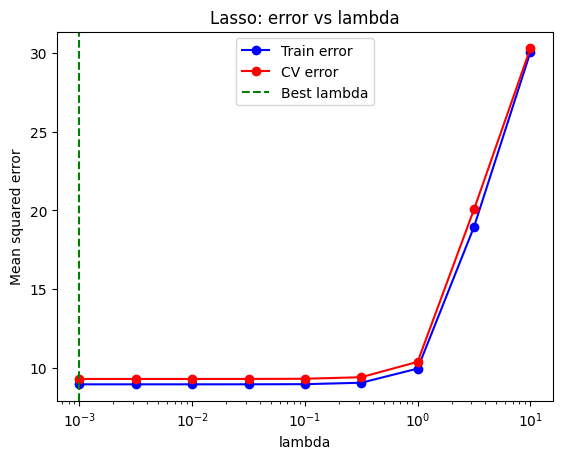

In [19]:
plt.semilogx(lambdas, train_err, 'b-o', label='Train error')
plt.semilogx(lambdas, cv_err, 'r-o', label='CV error')
plt.axvline(best_lambda, color='g', linestyle='--', label='Best lambda')
plt.xlabel('lambda')
plt.ylabel('Mean squared error')
plt.title('Lasso: error vs lambda')
plt.legend()
plt.show()